# Figure 2 - Translation Equivariance

In [1]:
# access fsw3d library by adding project root to sys.path
import sys, os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

### standard libraries
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

### fsw3d
from fast_volume_align_ot import utils, plots, transforms, signals, distances

In [2]:
COLORS = {
    'l2': 'darkgrey',
    'sw': '#8FB996',
    'rfsw': '#7C8ED0'
}

In [3]:
### generate a centered 3D Gaussian

N = 128
d = 3
dx = 1
sigma = 5

grid = transforms.Grids(N=N)

f = utils.gaussian_3d(N, sigma=sigma)
f = signals.Signal(f, dx=dx, d=d).preprocess_signals()[0]

In [4]:
### Compute the squared distances

n_shifts = 20
total_shift = 40  # in voxels
shifts = np.arange(0, total_shift+1, total_shift // n_shifts)

distances_l2 = np.zeros(n_shifts+1)
distances_sw = np.zeros(n_shifts+1)
distances_rfsw = np.zeros(n_shifts+1)

### Transforms of the reference volume

f_t = transforms.Transform(f, d=3, grid=grid).inverse_cdf_transform()[0]
f_tp, f_tn = transforms.Transform(f, d=3, grid=grid, apply_ramp=True).signed_inverse_cdf_transform()
f_tp, f_tn = f_tp[0], f_tn[0]

for idx, s in enumerate(shifts):

    g = transforms.translate_3d(f, 0, 0, s)  # shift volume along 1D

    ### Euclidean distance
    d_l2 = np.linalg.norm(f - g)**2
    distances_l2[idx] = d_l2

    ### sliced 2-Wasserstein distance
    g_t = transforms.Transform(g, d=3, grid=grid).inverse_cdf_transform()[0]

    d_sw = distances.compute_3d_sliced_wasserstein_distance(f_t, g_t, grid) / (4*np.pi)
    distances_sw[idx] = d_sw

    ### ramp-filtered sliced 2-Wasserstein distance
    g_tp, g_tn = transforms.Transform(g, d=3, grid=grid, apply_ramp=True).signed_inverse_cdf_transform()
    g_tp, g_tn = g_tp[0], g_tn[0]
    d_sw_p = distances.compute_3d_sliced_wasserstein_distance(f_tp, g_tp, grid) / (4*np.pi)
    d_sw_n = distances.compute_3d_sliced_wasserstein_distance(f_tn, g_tn, grid) / (4*np.pi)
    d_rfsw = (d_sw_p + d_sw_n) / 2
    distances_rfsw[idx] = d_rfsw

In [5]:
### Normalize to be on the same scale

dists_l2 = np.sqrt( distances_l2 / np.amax(distances_l2) )
dists_sw = np.sqrt( distances_sw / np.amax(distances_sw) )
dists_rfsw = np.sqrt( distances_rfsw / np.amax(distances_rfsw) )

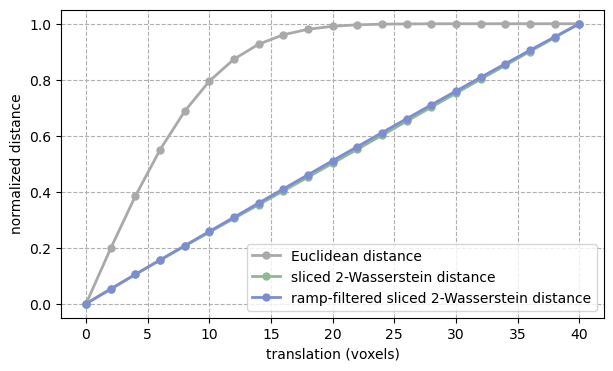

In [6]:
plt.figure(figsize=(7,4))
plt.plot(shifts, dists_l2, color=COLORS['l2'], marker='o', markersize=5, 
         linewidth=2, label='Euclidean distance')
plt.plot(shifts, dists_sw, color=COLORS['sw'], marker='o', markersize=5,
         linewidth=2, label='sliced 2-Wasserstein distance')
plt.plot(shifts, dists_rfsw, color=COLORS['rfsw'], marker='o', markersize=5,
         linewidth=2, label='ramp-filtered sliced 2-Wasserstein distance')

plt.xticks(np.arange(0, 41, 5))
plt.grid(which='major', linestyle='--')

plt.rc('axes', labelsize=12)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)
plt.rc('legend', fontsize=10)

plt.xlabel('translation (voxels)')
plt.ylabel('normalized distance')
# plt.title('distance over translations')
plt.legend()

# plt.savefig('Output/translation_equivariance.png', dpi=200, transparent=True)
plt.show()

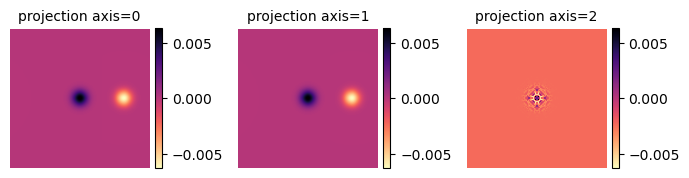

In [7]:
### view projection of the initial and final volumes

plots.orthogonal_2D_projection_plot(f - g, cmap='magma_r')